In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset

In [ ]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text= emotion_dataset['train']['text']
train_label= emotion_dataset['train']['label']

test_text= emotion_dataset['test']['text']
test_label= emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [ ]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [ ]:
label_names = emotion_dataset['train'].features['label'].names

In [ ]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [ ]:
df_train = pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }
)
df_test = pd.DataFrame(
    {
        'text':test_text,
        'label':[label_names[i] for i in test_label]
    }
)

In [ ]:
df_train.shape

(16000, 2)

In [ ]:
df_test.shape

(2000, 2)

In [ ]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [ ]:

df_train.isnull().sum()

,0
text,0
label,0


In [ ]:
df_test.isnull().sum()

,0
text,0
label,0


In [ ]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [ ]:
order = df_train['label'].value_counts().index

<Axes: xlabel='label', ylabel='count'>

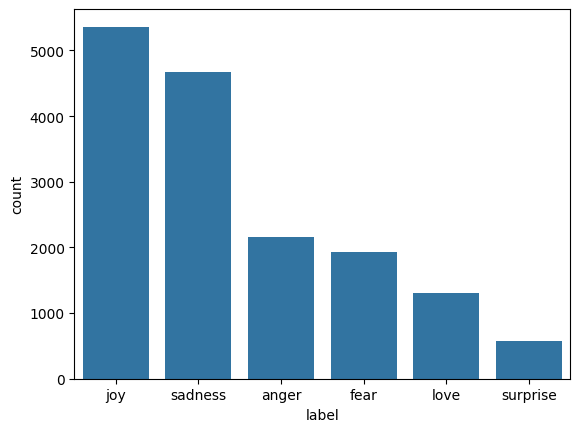

In [ ]:
sns.countplot(x = 'label',data =df_train,order=order)

In [ ]:

df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words = max_words,oov_token='<UNK>')
tokenizer.fit_on_texts(df_train['text'])
train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence = pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

In [ ]:
padded_train_sequence

array([[   2,  139,    3, ...,    0,    0,    0],
       [   2,   40,  101, ...,    0,    0,    0],
       [  17, 3060,    7, ...,    0,    0,    0],
       ...,
       [   2,    3,  327, ...,    0,    0,    0],
       [   2,    3,   14, ...,    0,    0,    0],
       [   2,   47,    7, ...,    0,    0,    0]], dtype=int32)

In [ ]:
train_labels = np.array(train_label)
test_labels = np.array(test_label)

train_labels
test_labels

array([0, 0, 0, ..., 1, 1, 4])

In [ ]:
num_classes = len(np.unique(label_names))
num_classes


6

In [ ]:
print(f"Vocabulary size: {len(tokenizer.word_index)}")
print(f"Number of classes: {num_classes}")
print(f"Number of sentence length: {padded_train_sequence.shape[1]}")

Vocabulary size: 15213
Number of classes: 6
Number of sentence length: 50


In [ ]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

class_weights_dict = dict(enumerate(class_weights))

In [ ]:
class_weights_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

In [ ]:
early_stopping

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN,LSTM,GRU, Dense, Dropout

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",  # Correct spelling
    metrics=["accuracy"]
)

In [ ]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    epochs = 20,
    validation_data = (padded_test_sequence,test_labels),
    callbacks = [early_stopping],
    class_weight = class_weights_dict,
    batch_size = 32
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.1581 - loss: 1.8883 - val_accuracy: 0.1075 - val_loss: 1.8050
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1590 - loss: 1.8005 - val_accuracy: 0.0480 - val_loss: 1.8199
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.1510 - loss: 1.7899 - val_accuracy: 0.1185 - val_loss: 1.7951
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1075 - loss: 1.8050
RNN Loss: 1.805008053779602
RNN Accuracy: 0.10750000178813934


In [ ]:
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",  # Correct spelling
    metrics=["accuracy"]
)

In [ ]:
lstm_model.fit(
    padded_train_sequence,
    train_labels,
    epochs = 20,
    validation_data = (padded_test_sequence,test_labels),
    callbacks = [early_stopping],
    class_weight = class_weights_dict,
    batch_size = 32
)

lstm_loss,lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.1698 - loss: 1.7950 - val_accuracy: 0.3485 - val_loss: 1.7647
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.1640 - loss: 1.7940 - val_accuracy: 0.0475 - val_loss: 1.7965
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.1582 - loss: 1.7927 - val_accuracy: 0.1170 - val_loss: 1.8058
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3485 - loss: 1.7647
LSTM Loss: 1.7646620273590088
LSTM Accuracy: 0.34850001335144043


In [ ]:
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",  # Correct spelling
    metrics=["accuracy"]
)

In [ ]:
gru_model.fit(
    padded_train_sequence,
    train_labels,
    epochs = 20,
    validation_data = (padded_test_sequence,test_labels),
    callbacks = [early_stopping],
    class_weight = class_weights_dict,
    batch_size = 32
)

gru_loss,gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.1361 - loss: 1.7964 - val_accuracy: 0.0795 - val_loss: 1.7900
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1578 - loss: 1.7958 - val_accuracy: 0.0800 - val_loss: 1.7983
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1602 - loss: 1.7944 - val_accuracy: 0.1130 - val_loss: 1.8088
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0795 - loss: 1.7900
GRU Loss: 1.7899757623672485
GRU Accuracy: 0.0794999971985817


In [ ]:
result_df = pd.DataFrame(
    {
        'Model':['rnn','lstm','gru'],
        'Test Loss':[rnn_loss,lstm_loss,gru_loss],
        'Test Accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy]
    }
).sort_values(by='Test Accuracy',ascending=False)

result_df

,Model,Test Loss,Test Accuracy
1,lstm,1.764662,0.3485
0,rnn,1.805008,0.1075
2,gru,1.789976,0.0795


In [ ]:
from tensorflow.keras.layers import Bidirectional
BIGRU = Sequential([
    Embedding(input_dim=max_words, output_dim=300,input_length = 50),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

BIGRU.compile(optimizer = 'adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
BIGRU.summary()


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_13 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
BIGRU.fit(
    padded_train_sequence,
    train_labels,
    epochs = 20,
    validation_data = (padded_test_sequence,test_labels),
    callbacks = [early_stopping],
    class_weight = class_weights_dict,
    batch_size = 32
  )

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.5733 - loss: 1.0299 - val_accuracy: 0.8820 - val_loss: 0.3725
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9136 - loss: 0.2404 - val_accuracy: 0.9170 - val_loss: 0.2139
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9448 - loss: 0.1431 - val_accuracy: 0.9140 - val_loss: 0.2338
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9584 - loss: 0.1143 - val_accuracy: 0.9230 - val_loss: 0.2148
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9693 - loss: 0.0838 - val_accuracy: 0.9155 - val_loss: 0.2842


In [ ]:
BIGRU_loss,BIGRU_accuracy = BIGRU.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {BIGRU_loss}")
print(f"GRU Accuracy: {BIGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9170 - loss: 0.2139
GRU Loss: 0.21392814815044403
GRU Accuracy: 0.9169999957084656


In [ ]:
BILSTM = Sequential([
    Embedding(input_dim=max_words, output_dim=300,input_length = 50),
    Bidirectional(LSTM(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

BILSTM.compile(optimizer = 'adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
BILSTM.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_14 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
BILSTM.fit(
    padded_train_sequence,
    train_labels,
    epochs = 20,
    validation_data = (padded_test_sequence,test_labels),
    callbacks = [early_stopping],
    class_weight = class_weights_dict,
    batch_size = 32
  )

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.5783 - loss: 1.0725 - val_accuracy: 0.8765 - val_loss: 0.3940
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9118 - loss: 0.2863 - val_accuracy: 0.8940 - val_loss: 0.3429
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9360 - loss: 0.1919 - val_accuracy: 0.9030 - val_loss: 0.2997


In [ ]:
BILSTM_loss,BILSTM_accuracy = BILSTM.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {BILSTM_loss}")
print(f"GRU Accuracy: {BILSTM_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8765 - loss: 0.3940
GRU Loss: 0.3940311074256897
GRU Accuracy: 0.8765000104904175


In [ ]:
from sklearn.metrics import confusion_matrix,classification_report

BIGRU_Prediction = np.argmax(BIGRU.predict(padded_test_sequence),axis =1)
BIGRU_Prediction

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


array([0, 0, 0, ..., 1, 1, 5])

In [ ]:
test_labels

array([0, 0, 0, ..., 1, 1, 4])

<Axes: >

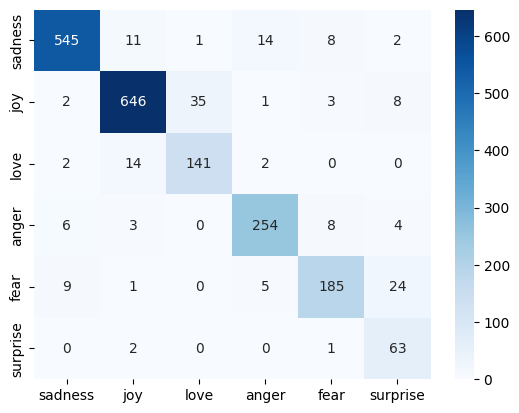

In [ ]:
sns.heatmap(confusion_matrix(test_labels,BIGRU_Prediction),annot=True,fmt = 'd',cmap = 'Blues',xticklabels=label_names,yticklabels=label_names)

In [ ]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BIGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [ ]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir,exist_ok = True)

BIGRU.save(os.path.join(model_dir,'BIGRU_model.keras'))

with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)